# AI4015 Assignment Beta, Question 4
Roll number 23K-0008. LLM sentiment evaluation: Stage 1 (zero-shot) and Stage 2 (improved prompt).

Implementation choices used in this notebook: Wilson score interval with z = 1.96; sample standard deviation (n − 1); BLEU-4 with uniform weights and no smoothing (no n-gram precision is zero here, so smoothing would change nothing); ROUGE without stemming; METEOR from NLTK with alpha 0.9, beta 3, gamma 0.5, exact and Porter-stem matching, and the WordNet synonym stage switched off because the WordNet data could not be downloaded.

## 1. Importing required libraries

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer

plt.rcParams['font.family'] = ['Liberation Serif', 'DejaVu Serif']
plt.rcParams['font.size'] = 10
pd.options.display.float_format = '{:.6f}'.format
class_names = ['Positive', 'Negative', 'Neutral']

## 2. Stage 1 confusion matrix (rows = actual, columns = predicted)

In [2]:
stage1_matrix = np.array([[100, 5, 15], [8, 80, 12], [20, 10, 50]])
display(pd.DataFrame(stage1_matrix, index=class_names, columns=class_names))

,Positive,Negative,Neutral
Positive,100,5,15
Negative,8,80,12
Neutral,20,10,50


## 3. Accuracy and 95% Wilson confidence interval

In [3]:
def accuracy_with_wilson_interval(matrix, z=1.96):
    total = matrix.sum()
    correct = np.trace(matrix)
    accuracy = correct / total
    denominator = 1 + z ** 2 / total
    centre = (accuracy + z ** 2 / (2 * total)) / denominator
    half_width = z * math.sqrt(accuracy * (1 - accuracy) / total + z ** 2 / (4 * total ** 2)) / denominator
    return {'total': total, 'correct': correct, 'accuracy': accuracy, 'denominator': denominator,
            'centre': centre, 'half_width': half_width, 'lower': centre - half_width, 'upper': centre + half_width}

stage1_accuracy = accuracy_with_wilson_interval(stage1_matrix)
for name, value in stage1_accuracy.items():
    print(f'{name:12s} {value:.6f}')
print(f"95% CI: {stage1_accuracy['lower'] * 100:.2f}% to {stage1_accuracy['upper'] * 100:.2f}%")

total        300.000000
correct      230.000000
accuracy     0.766667
denominator  1.012805
centre       0.763295
half_width   0.047677
lower        0.715618
upper        0.810973
95% CI: 71.56% to 81.10%


## 4. Per-class precision, recall and F1

In [4]:
def per_class_table(matrix):
    true_positive = np.diag(matrix)
    false_positive = matrix.sum(axis=0) - true_positive
    false_negative = matrix.sum(axis=1) - true_positive
    support = matrix.sum(axis=1)
    precision = true_positive / (true_positive + false_positive)
    recall = true_positive / (true_positive + false_negative)
    f1 = 2 * precision * recall / (precision + recall)
    return pd.DataFrame({'TP': true_positive, 'FP': false_positive, 'FN': false_negative, 'Support': support,
                         'Precision': precision, 'Recall': recall, 'F1': f1}, index=class_names)

stage1_table = per_class_table(stage1_matrix)
display(stage1_table)

,TP,FP,FN,Support,Precision,Recall,F1
Positive,100,28,20,120,0.781250,0.833333,0.806452
Negative,80,15,20,100,0.842105,0.800000,0.820513
Neutral,50,27,30,80,0.649351,0.625000,0.636943


## 5. Macro, weighted and micro F1

In [5]:
def averaged_f1(table):
    macro = table['F1'].mean()
    weighted = (table['F1'] * table['Support']).sum() / table['Support'].sum()
    total_tp = table['TP'].sum()
    micro_precision = total_tp / (total_tp + table['FP'].sum())
    micro_recall = total_tp / (total_tp + table['FN'].sum())
    micro = 2 * micro_precision * micro_recall / (micro_precision + micro_recall)
    return {'macro_f1': macro, 'weighted_f1': weighted, 'micro_f1': micro,
            'micro_precision': micro_precision, 'micro_recall': micro_recall}

stage1_averages = averaged_f1(stage1_table)
for name, value in stage1_averages.items():
    print(f'{name:16s} {value:.6f}')

macro_f1         0.754636
weighted_f1      0.765936
micro_f1         0.766667
micro_precision  0.766667
micro_recall     0.766667


## 6. Stage 2 confusion matrix

In [6]:
stage2_matrix = np.array([[106, 4, 10], [6, 84, 10], [9, 7, 64]])
display(pd.DataFrame(stage2_matrix, index=class_names, columns=class_names))

,Positive,Negative,Neutral
Positive,106,4,10
Negative,6,84,10
Neutral,9,7,64


## 7. Stage 2 metrics

In [7]:
stage2_accuracy = accuracy_with_wilson_interval(stage2_matrix)
stage2_table = per_class_table(stage2_matrix)
stage2_averages = averaged_f1(stage2_table)
for name, value in stage2_accuracy.items():
    print(f'{name:12s} {value:.6f}')
print(f"95% CI: {stage2_accuracy['lower'] * 100:.2f}% to {stage2_accuracy['upper'] * 100:.2f}%")
display(stage2_table)
for name, value in stage2_averages.items():
    print(f'{name:16s} {value:.6f}')

total        300.000000
correct      254.000000
accuracy     0.846667
denominator  1.012805
centre       0.842284
half_width   0.040751
lower        0.801533
upper        0.883034
95% CI: 80.15% to 88.30%


,TP,FP,FN,Support,Precision,Recall,F1
Positive,106,15,14,120,0.876033,0.883333,0.879668
Negative,84,11,16,100,0.884211,0.840000,0.861538
Neutral,64,20,16,80,0.761905,0.800000,0.780488


macro_f1         0.840565
weighted_f1      0.847177
micro_f1         0.846667
micro_precision  0.846667
micro_recall     0.846667


## 8. Stage 1 versus Stage 2

In [8]:
comparison_rows = {'Accuracy': (stage1_accuracy['accuracy'], stage2_accuracy['accuracy'])}
for class_name in class_names:
    for metric in ['Precision', 'Recall', 'F1']:
        comparison_rows[f'{class_name} {metric}'] = (stage1_table.loc[class_name, metric], stage2_table.loc[class_name, metric])
comparison_rows['Macro F1'] = (stage1_averages['macro_f1'], stage2_averages['macro_f1'])
comparison_rows['Weighted F1'] = (stage1_averages['weighted_f1'], stage2_averages['weighted_f1'])
comparison_rows['Micro F1'] = (stage1_averages['micro_f1'], stage2_averages['micro_f1'])
comparison_table = pd.DataFrame(comparison_rows, index=['Stage 1', 'Stage 2']).T
comparison_table['Change'] = comparison_table['Stage 2'] - comparison_table['Stage 1']
display(comparison_table)

,Stage 1,Stage 2,Change
Accuracy,0.766667,0.846667,0.080000
Positive Precision,0.781250,0.876033,0.094783
Positive Recall,0.833333,0.883333,0.050000
Positive F1,0.806452,0.879668,0.073216
Negative Precision,0.842105,0.884211,0.042105
Negative Recall,0.800000,0.840000,0.040000
Negative F1,0.820513,0.861538,0.041026
Neutral Precision,0.649351,0.761905,0.112554
Neutral Recall,0.625000,0.800000,0.175000
Neutral F1,0.636943,0.780488,0.143545


## 9. Few-shot prompt stability (sample standard deviation, n − 1)

In [9]:
run_accuracies = np.array([0.847, 0.840, 0.853, 0.837, 0.850])
run_mean = run_accuracies.mean()
deviations = run_accuracies - run_mean
squared_deviations = deviations ** 2
sample_variance = squared_deviations.sum() / (len(run_accuracies) - 1)
sample_standard_deviation = math.sqrt(sample_variance)
print(pd.DataFrame({'Accuracy': run_accuracies, 'Deviation': deviations, 'Squared deviation': squared_deviations}))
print(f'sum        {run_accuracies.sum():.6f}')
print(f'mean       {run_mean:.6f}')
print(f'sum sq dev {squared_deviations.sum():.8f}')
print(f'variance   {sample_variance:.8f}')
print(f'std dev    {sample_standard_deviation:.6f}')
print(f'mean +/- sd  {run_mean:.4f} +/- {sample_standard_deviation:.4f}')

   Accuracy  Deviation  Squared deviation
0  0.847000   0.001600           0.000003
1  0.840000  -0.005400           0.000029
2  0.853000   0.007600           0.000058
3  0.837000  -0.008400           0.000071
4  0.850000   0.004600           0.000021
sum        4.227000
mean       0.845400
sum sq dev 0.00018120
variance   0.00004530
std dev    0.006731
mean +/- sd  0.8454 +/- 0.0067


## 10. BLEU-4, ROUGE-1, ROUGE-2, ROUGE-L and METEOR
Tokenisation: split on single spaces (the sentences are already lower-cased with punctuation removed).

In [10]:
reference_text = 'the delivery was late but the product quality is good'
candidate_text = 'the product quality is good but delivery was slow'
reference_tokens = reference_text.split()
candidate_tokens = candidate_text.split()

def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

rows = []
precisions = []
for n in range(1, 5):
    candidate_counts = ngram_counts(candidate_tokens, n)
    reference_counts = ngram_counts(reference_tokens, n)
    clipped_matches = sum(min(count, reference_counts[gram]) for gram, count in candidate_counts.items())
    candidate_total = sum(candidate_counts.values())
    precisions.append(clipped_matches / candidate_total)
    rows.append({'n': n, 'clipped matches': clipped_matches, 'candidate n-grams': candidate_total,
                 'reference n-grams': sum(reference_counts.values()), 'precision': clipped_matches / candidate_total})
display(pd.DataFrame(rows))

brevity_penalty = math.exp(1 - len(reference_tokens) / len(candidate_tokens)) if len(candidate_tokens) < len(reference_tokens) else 1.0
bleu4_manual = brevity_penalty * math.exp(sum(math.log(p) for p in precisions) / 4)
bleu4_nltk = sentence_bleu([reference_tokens], candidate_tokens, weights=(0.25, 0.25, 0.25, 0.25))
bleu4_nltk_smoothed = sentence_bleu([reference_tokens], candidate_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=SmoothingFunction().method1)
print(f'brevity penalty        {brevity_penalty:.6f}')
print(f'BLEU-4 manual          {bleu4_manual:.6f}')
print(f'BLEU-4 NLTK no smooth  {bleu4_nltk:.6f}')
print(f'BLEU-4 NLTK method1    {bleu4_nltk_smoothed:.6f}')

,n,clipped matches,candidate n-grams,reference n-grams,precision
0,1,8,9,10,0.888889
1,2,5,8,9,0.625000
2,3,3,7,8,0.428571
3,4,2,6,7,0.333333


brevity penalty        0.894839
BLEU-4 manual          0.474955
BLEU-4 NLTK no smooth  0.474955
BLEU-4 NLTK method1    0.474955


In [11]:
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False)
rouge_scores = scorer.score(reference_text, candidate_text)
rouge_table = pd.DataFrame({name: {'Precision': score.precision, 'Recall': score.recall, 'F1': score.fmeasure} for name, score in rouge_scores.items()}).T
display(rouge_table)

,Precision,Recall,F1
rouge1,0.888889,0.800000,0.842105
rouge2,0.625000,0.555556,0.588235
rougeL,0.555556,0.500000,0.526316


In [12]:
class WordNetWithoutSynonyms:
    def synsets(self, *arguments, **keyword_arguments):
        return []

meteor_value = meteor_score([reference_tokens], candidate_tokens, alpha=0.9, beta=3, gamma=0.5, wordnet=WordNetWithoutSynonyms())
matched_words = 8
meteor_precision = matched_words / len(candidate_tokens)
meteor_recall = matched_words / len(reference_tokens)
meteor_fmean = meteor_precision * meteor_recall / (0.9 * meteor_precision + 0.1 * meteor_recall)
chunks = 3
meteor_penalty = 0.5 * (chunks / matched_words) ** 3
meteor_manual = meteor_fmean * (1 - meteor_penalty)
print(f'precision {meteor_precision:.6f}  recall {meteor_recall:.6f}  Fmean {meteor_fmean:.6f}')
print(f'penalty   {meteor_penalty:.6f}')
print(f'METEOR manual {meteor_manual:.6f}')
print(f'METEOR NLTK   {meteor_value:.6f}')

precision 0.888889  recall 0.800000  Fmean 0.808081
penalty   0.026367
METEOR manual 0.786774
METEOR NLTK   0.786774


## 11. Perplexity

In [13]:
token_probabilities = np.array([0.60, 0.40, 0.50, 0.80, 0.70, 0.30, 0.25, 0.50, 0.20])
log_probabilities = np.log(token_probabilities)
print(pd.DataFrame({'p': token_probabilities, 'ln p': log_probabilities}))
sum_log_probabilities = log_probabilities.sum()
average_negative_log_probability = -sum_log_probabilities / len(token_probabilities)
perplexity = math.exp(average_negative_log_probability)
print(f'sum of ln p     {sum_log_probabilities:.6f}')
print(f'average -ln p   {average_negative_log_probability:.6f}')
print(f'perplexity      {perplexity:.6f}')

         p      ln p
0 0.600000 -0.510826
1 0.400000 -0.916291
2 0.500000 -0.693147
3 0.800000 -0.223144
4 0.700000 -0.356675
5 0.300000 -1.203973
6 0.250000 -1.386294
7 0.500000 -0.693147
8 0.200000 -1.609438
sum of ln p     -7.592934
average -ln p   0.843659
perplexity      2.324859


## 12. Final results

In [14]:
final_results = pd.DataFrame({
    'Metric': ['BLEU-4', 'ROUGE-1 F1', 'ROUGE-2 F1', 'ROUGE-L F1', 'METEOR', 'Perplexity'],
    'Value': [bleu4_nltk, rouge_table.loc['rouge1', 'F1'], rouge_table.loc['rouge2', 'F1'], rouge_table.loc['rougeL', 'F1'], meteor_value, perplexity]})
display(final_results)
summary = pd.DataFrame({
    'Stage 1': [stage1_accuracy['accuracy'], stage1_accuracy['lower'], stage1_accuracy['upper']],
    'Stage 2': [stage2_accuracy['accuracy'], stage2_accuracy['lower'], stage2_accuracy['upper']]},
    index=['Accuracy', 'CI lower', 'CI upper'])
display(summary)
print(f'Prompt stability: {run_mean:.4f} +/- {sample_standard_deviation:.4f}')

,Metric,Value
0,BLEU-4,0.474955
1,ROUGE-1 F1,0.842105
2,ROUGE-2 F1,0.588235
3,ROUGE-L F1,0.526316
4,METEOR,0.786774
5,Perplexity,2.324859


,Stage 1,Stage 2
Accuracy,0.766667,0.846667
CI lower,0.715618,0.801533
CI upper,0.810973,0.883034


Prompt stability: 0.8454 +/- 0.0067


## 13. Graphs

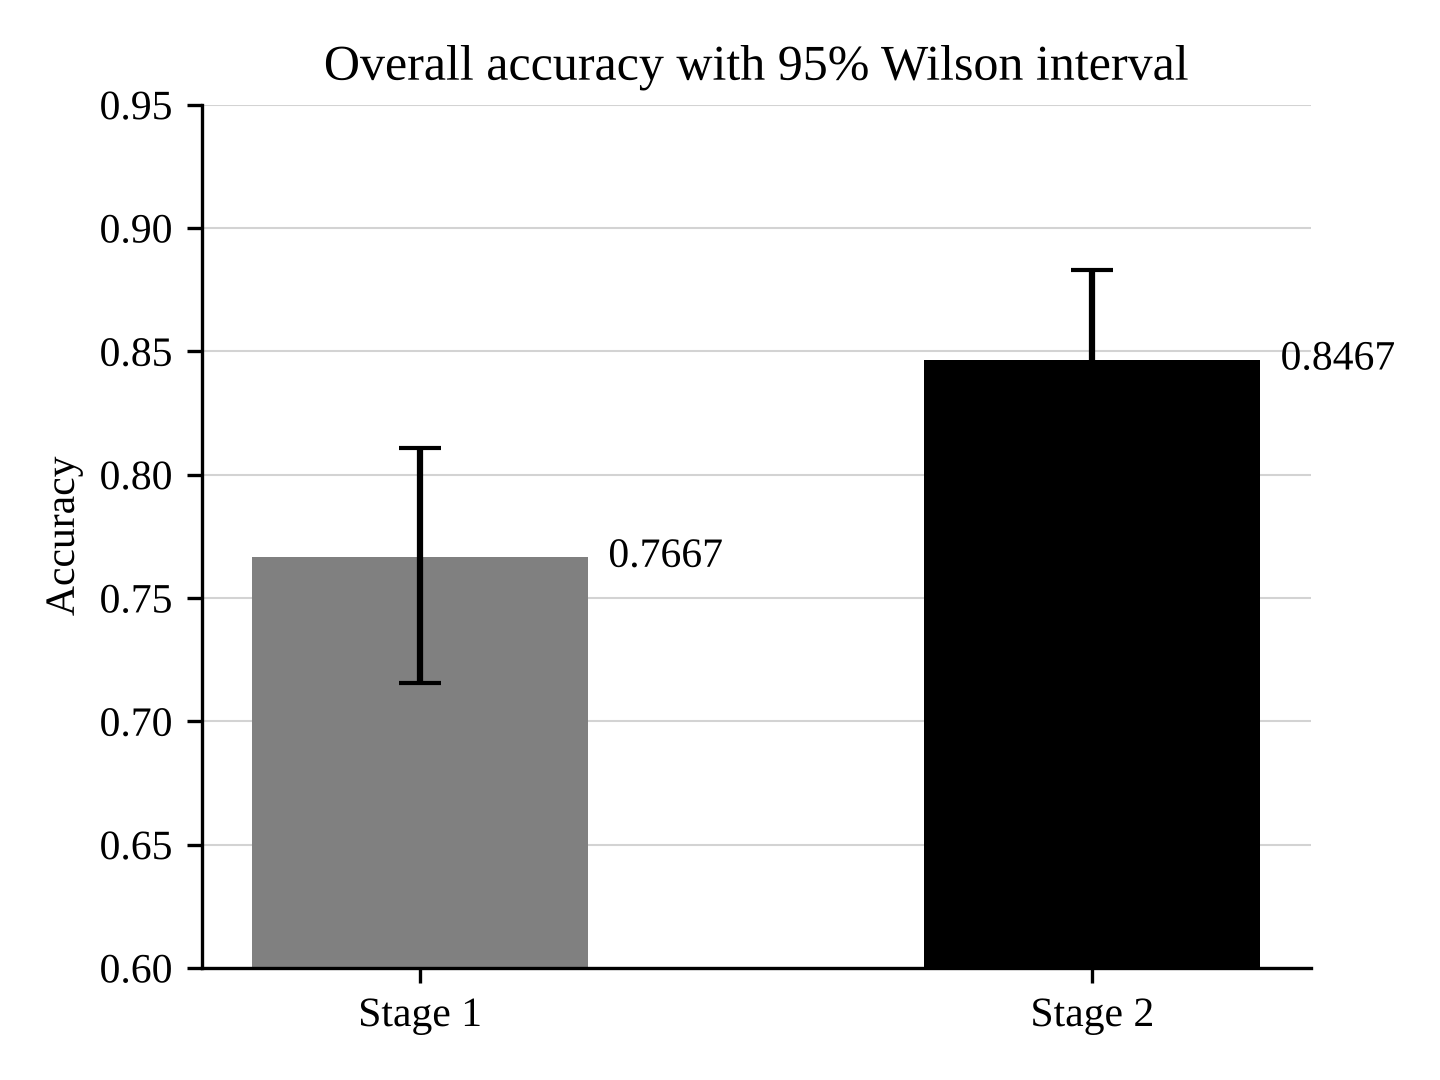

In [15]:
def style_axis(axis):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    axis.grid(axis='y', color='lightgray', linewidth=0.5)
    axis.set_axisbelow(True)

figure, axis = plt.subplots(figsize=(4.8, 3.6))
accuracies = [stage1_accuracy['accuracy'], stage2_accuracy['accuracy']]
lowers = [stage1_accuracy['accuracy'] - stage1_accuracy['lower'], stage2_accuracy['accuracy'] - stage2_accuracy['lower']]
uppers = [stage1_accuracy['upper'] - stage1_accuracy['accuracy'], stage2_accuracy['upper'] - stage2_accuracy['accuracy']]
bars = axis.bar(['Stage 1', 'Stage 2'], accuracies, width=0.5, color=['gray', 'black'], yerr=[lowers, uppers], capsize=5)
for bar, value in zip(bars, accuracies):
    axis.text(bar.get_x() + bar.get_width() / 2 + 0.28, value, f'{value:.4f}', ha='left', va='center')
axis.set_ylim(0.6, 0.95)
axis.set_ylabel('Accuracy')
axis.set_title('Overall accuracy with 95% Wilson interval')
style_axis(axis)
figure.tight_layout()
figure.savefig('fig_accuracy.png', dpi=300)
plt.close(figure)
display(Image('fig_accuracy.png', width=420))

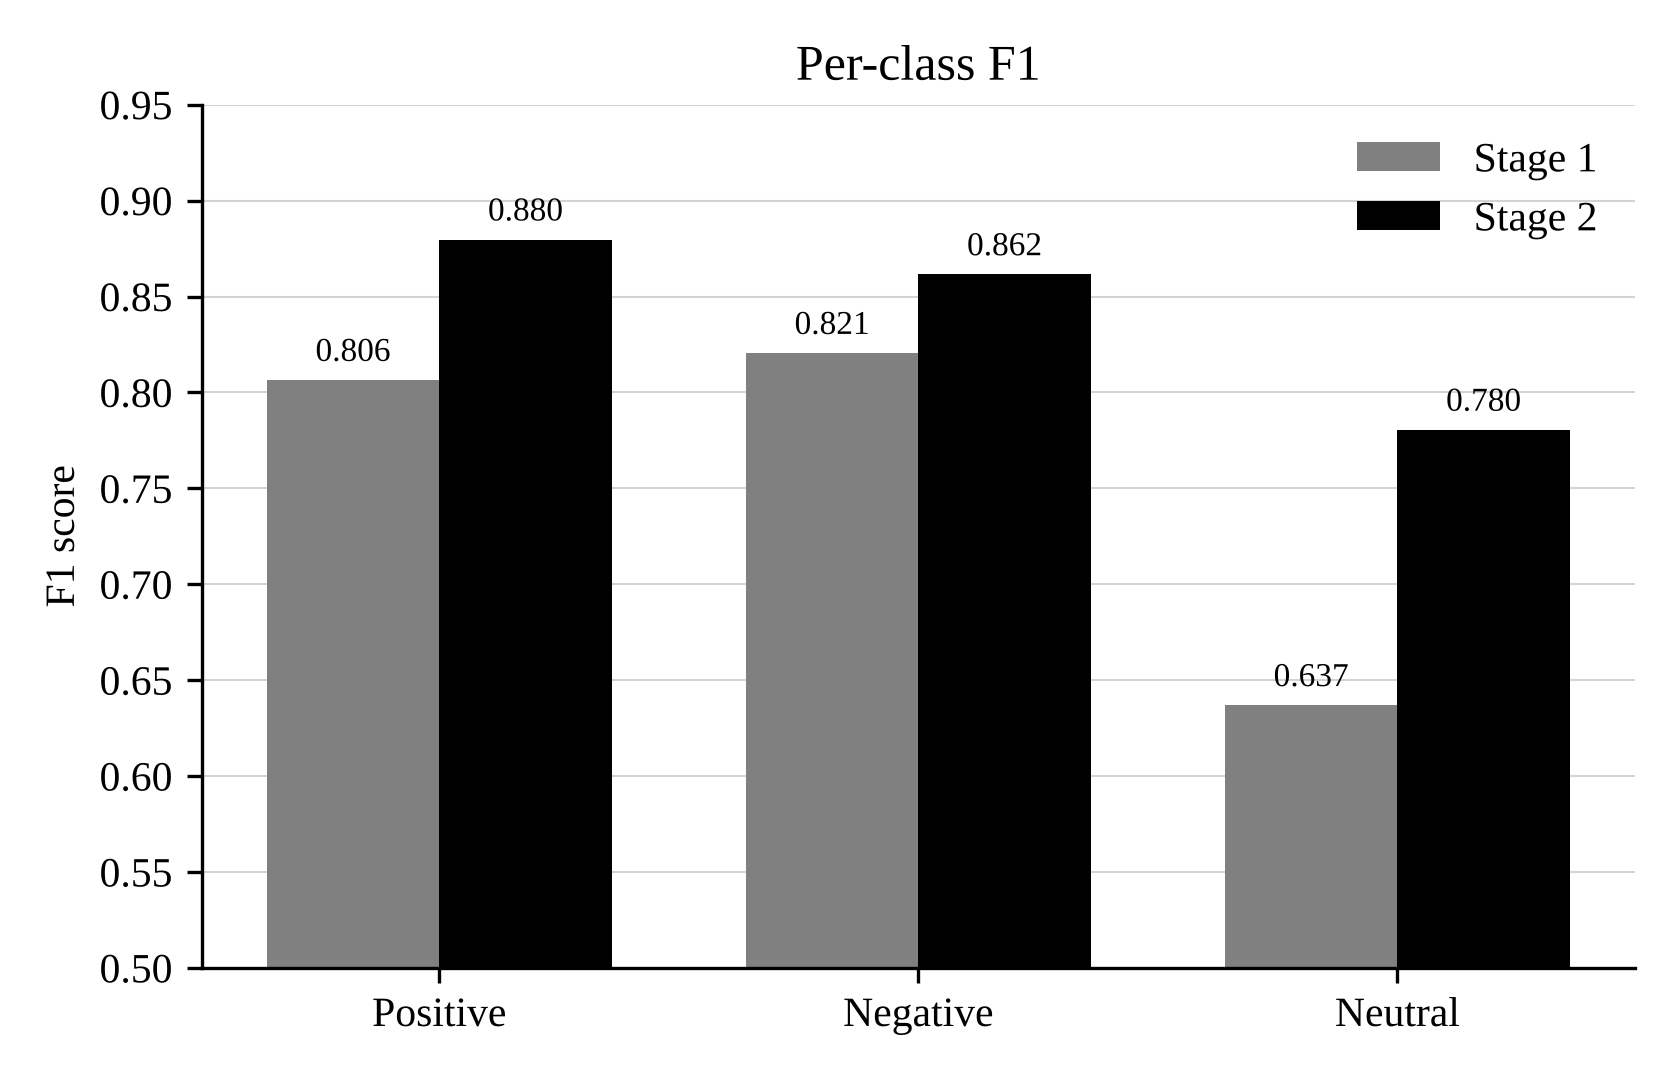

In [16]:
figure, axis = plt.subplots(figsize=(5.6, 3.6))
positions = np.arange(3)
width = 0.36
bars_one = axis.bar(positions - width / 2, stage1_table['F1'], width, label='Stage 1', color='gray')
bars_two = axis.bar(positions + width / 2, stage2_table['F1'], width, label='Stage 2', color='black')
for bars in (bars_one, bars_two):
    for bar in bars:
        axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=8)
axis.set_xticks(positions)
axis.set_xticklabels(class_names)
axis.set_ylim(0.5, 0.95)
axis.set_ylabel('F1 score')
axis.set_title('Per-class F1')
axis.legend(frameon=False)
style_axis(axis)
figure.tight_layout()
figure.savefig('fig_class_f1.png', dpi=300)
plt.close(figure)
display(Image('fig_class_f1.png', width=480))

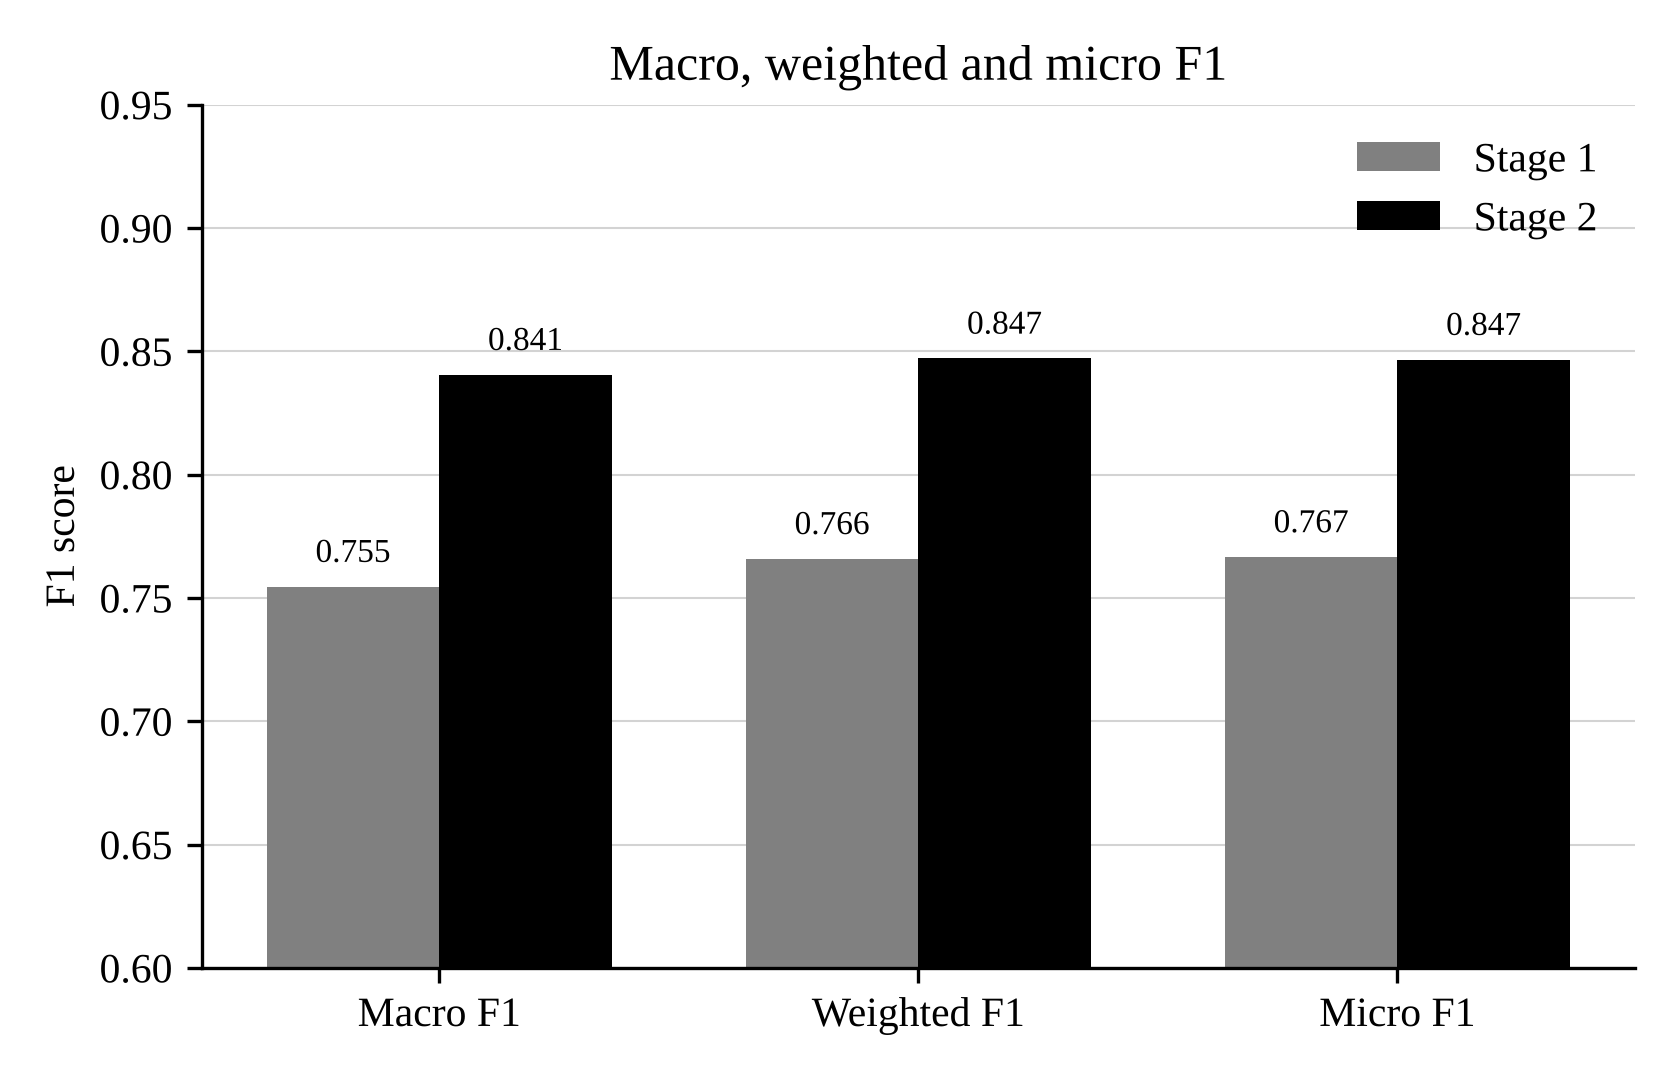

In [17]:
figure, axis = plt.subplots(figsize=(5.6, 3.6))
average_names = ['Macro F1', 'Weighted F1', 'Micro F1']
stage1_values = [stage1_averages['macro_f1'], stage1_averages['weighted_f1'], stage1_averages['micro_f1']]
stage2_values = [stage2_averages['macro_f1'], stage2_averages['weighted_f1'], stage2_averages['micro_f1']]
positions = np.arange(3)
bars_one = axis.bar(positions - width / 2, stage1_values, width, label='Stage 1', color='gray')
bars_two = axis.bar(positions + width / 2, stage2_values, width, label='Stage 2', color='black')
for bars in (bars_one, bars_two):
    for bar in bars:
        axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=8)
axis.set_xticks(positions)
axis.set_xticklabels(average_names)
axis.set_ylim(0.6, 0.95)
axis.set_ylabel('F1 score')
axis.set_title('Macro, weighted and micro F1')
axis.legend(frameon=False)
style_axis(axis)
figure.tight_layout()
figure.savefig('fig_average_f1.png', dpi=300)
plt.close(figure)
display(Image('fig_average_f1.png', width=480))

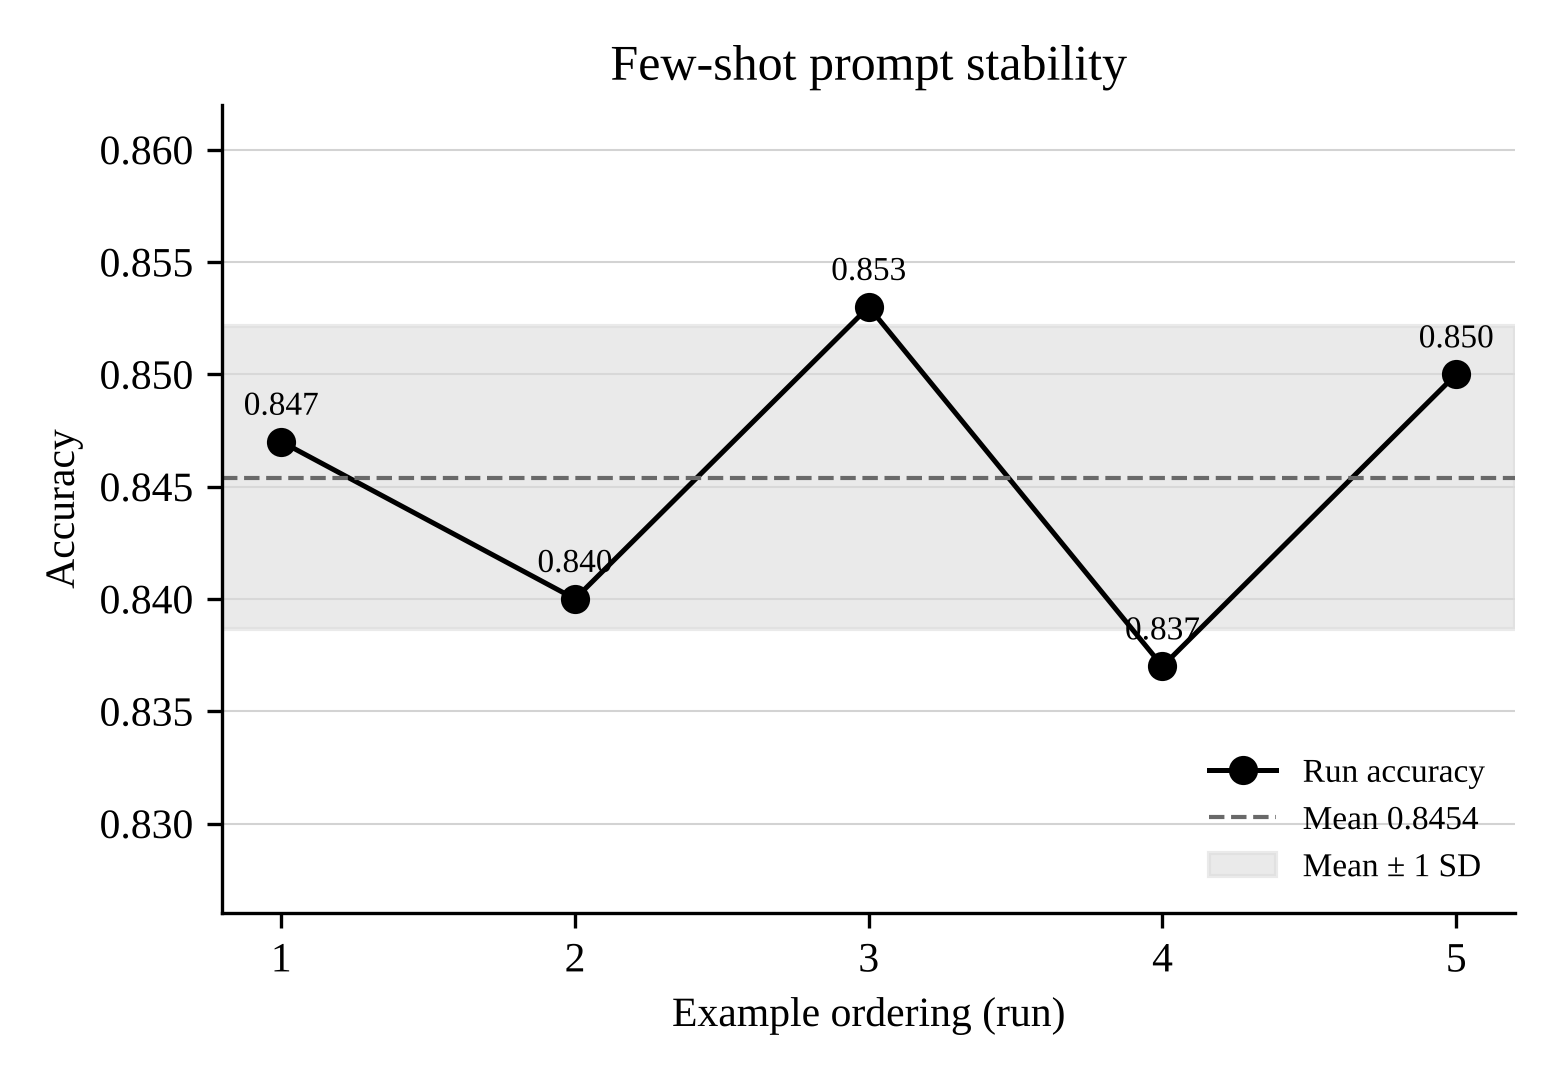

In [18]:
figure, axis = plt.subplots(figsize=(5.2, 3.6))
run_numbers = np.arange(1, 6)
axis.plot(run_numbers, run_accuracies, color='black', marker='o', linewidth=1.2, label='Run accuracy')
axis.axhline(run_mean, color='dimgray', linestyle='--', linewidth=1, label=f'Mean {run_mean:.4f}')
axis.axhspan(run_mean - sample_standard_deviation, run_mean + sample_standard_deviation, color='gainsboro', alpha=0.6, label='Mean ± 1 SD')
for run_number, value in zip(run_numbers, run_accuracies):
    axis.text(run_number, value + 0.0012, f'{value:.3f}', ha='center', fontsize=8)
axis.set_xticks(run_numbers)
axis.set_ylim(0.826, 0.862)
axis.set_xlabel('Example ordering (run)')
axis.set_ylabel('Accuracy')
axis.set_title('Few-shot prompt stability')
axis.legend(frameon=False, loc='lower right', fontsize=8)
style_axis(axis)
figure.tight_layout()
figure.savefig('fig_stability.png', dpi=300)
plt.close(figure)
display(Image('fig_stability.png', width=450))